> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage5_lineage_and_evaluation_en.ipynb`)](../en/stage5_lineage_and_evaluation_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/05_stage5_lineage_and_eval_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage5)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → **[▶ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)**

---

# Stage 5. [검증 & 배포 게이트] 4-Tier End-to-End 데이터 리니지 · Golden CQ 감사 & Boundary 50회 벤치마크
## Step 5.1 원천 파일→청크→규칙→약정→CQ 4-Tier 리니지 검증 · Step 5.2 Golden CQ 5종 및 Boundary 10건×5회(50 Trials) 배포 게이트

Stage 5는 전체 엔지니어링 흐름의 최종 단계인 **Phase 8(검증 및 배포 게이트)**을 수행합니다. `mcp_stage5_lineage_and_eval`과 `pipeline/validator.py`를 통해 **(1) 원천 CSV/가이드 파일 → SHA-256 청크 → 도메인 규칙 → 고객 약정 → Golden CQ 답변으로 이어지는 4-Tier 데이터 리니지**를 추적하고, **(2) 독립 검증 SQL(`verification_sql`) 대조 기반 Golden CQ 5종 전수 감사**, **(3) 경계 조건 10건 × 5회 반복(총 50 Trials) 안정성·일관성·의도 유지율 평가**, **(4) Gate 1 ~ Gate 5 프로덕션 배포 승인 판정**을 완결합니다.

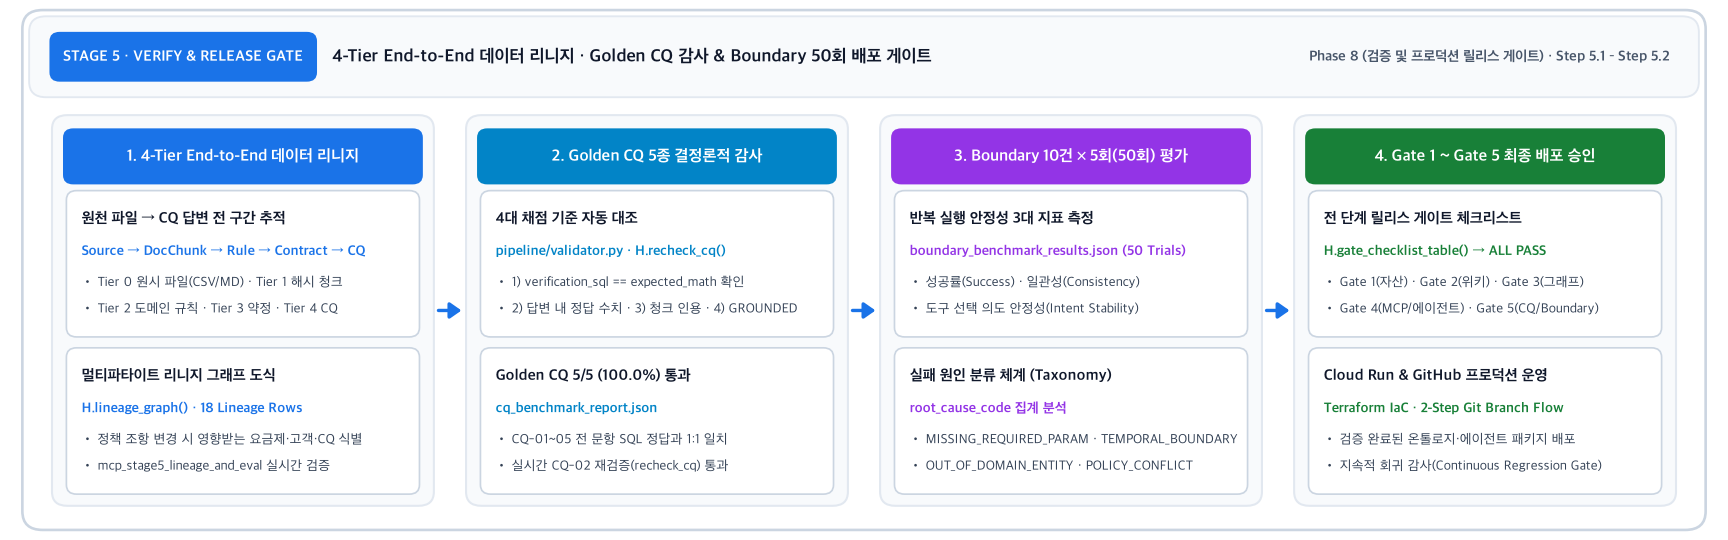


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 8a: 4-Tier 데이터 리니지 검증] `mcp_stage5_lineage_and_eval` 실행 · 리니지 조인(`%%bqsql`) · 멀티파타이트 리니지 설계 도식


In [2]:
res_s5 = server.execute_tool("mcp_stage5_lineage_and_eval", {"steps": ["build_4tier_lineage", "run_golden_cq_suite", "diagnose_boundary_failures"]})
H.show_tool(res_s5)


**`mcp_stage5_lineage_and_eval`** · status `SUCCESS` · steps `build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures` · BigQuery jobs 1 (432 ms)

리니지 조인 12행 · 최근 검증 리포트: {'evaluated_at': '2026-09-27T19:42:34+09:00', 'total_cqs': 5, 'passed': 5, 'accuracy_rate': 100.0, 'method': 'verification_sql(BigQuery) vs expected_math + live agent answer (Vertex AI gemini-3.8-flash + BigQuery MCP)'}

- `job_1xGky0ayPohcdsG6Lv2bLB9wypFX`

In [3]:
%%bqsql df_lineage
SELECT c.contract_id, c.customer_id, d.device_name, p.plan_name, s.policy_id,
       e.rule_id, e.source_chunk_id, ch.content_sha256 AS anchor, ch.source_file
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d ON d.device_id = c.device_id
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p ON p.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s ON s.device_id = c.device_id AND s.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e ON e.plan_id = c.plan_id
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = e.source_chunk_id
ORDER BY c.contract_id, e.rule_id


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


,contract_id,customer_id,device_name,plan_name,policy_id,rule_id,source_chunk_id,anchor,source_file
0,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
1,CONTRACT_DEMO_101,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,POL-2026-002,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
2,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
3,CONTRACT_DEMO_102,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,POL-2026-001,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
4,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
5,CONTRACT_DEMO_103,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,POL-2026-005,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
6,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
7,CONTRACT_DEMO_104,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md
8,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_SIX_PLAN_180D,DOC_CHUNK_002,anchor_3003b683cea0,sample_policy_guide.md
9,CONTRACT_DEMO_105,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,<NA>,RULE_TCO_24M,DOC_CHUNK_005,anchor_4fbaf9c5cba8,sample_welfare_exemption_guide.md


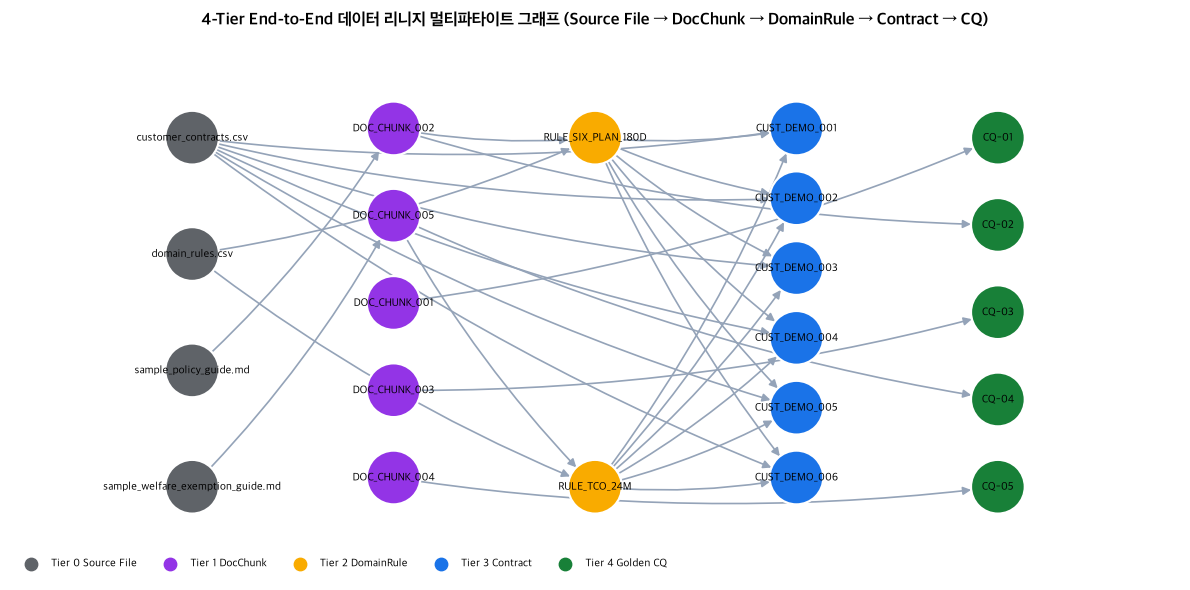

In [4]:
H.show(df_lineage)
cq_rep = H.read_json("data/output/cq_benchmark_report.json")
lnodes, ledges = H.lineage_graph(H.pdf(df_lineage).to_dict("records"), cq_rep["test_results"])
H.draw_graph(lnodes, ledges,
             H.t("4-Tier End-to-End 데이터 리니지 멀티파타이트 그래프 (Source File → DocChunk → DomainRule → Contract → CQ)",
                 "4-Tier End-to-End Data Lineage Multipartite Graph (Source File → DocChunk → DomainRule → Contract → CQ)"),
             layout="layers", figsize=(12, 6.0),
             legend={"Tier 0 Source File": "#5F6368", "Tier 1 DocChunk": "#9334E6", "Tier 2 DomainRule": "#F9AB00",
                     "Tier 3 Contract": "#1A73E8", "Tier 4 Golden CQ": "#188038"})


### 2. [Phase 8b: Golden CQ 5종 정량 감사 (`pipeline/validator.py`)] 벤치마크 리포트 분석 및 실시간 에이전트 4대 채점 조건 재검증 (`recheck_cq`)


**Golden CQ Benchmark `STARTER_GOLDEN_CQ_LIVE`** · Evaluated `2026-09-27T19:42:34+09:00` · Model `gemini-3.8-flash` · Passed **`5/5 (100.0%)`**

,cq_id,category,status,verification_status,grounded_chunk,llm_tokens,elapsed_s,verification_job_id
0,CQ-01,Single-Hop Lookup,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_001,6554,12.13,job_kp_mf4q1vXzjXTvAaC8R2o1vrqH3
1,CQ-02,Two-Hop Subsidy,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_002,4343,15.48,job_HcJcufLz5VTMkgfX4FA1GWCyJBgP
2,CQ-03,Multi-Hop Penalty,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_003,6495,18.67,job_qkPaBb51rD8lypnG8j32JAhGIftX
3,CQ-04,24M TCO Optimization,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_005,6466,18.44,job_ire8VaTtqNi0DBcqKT79tYv_Da7R
4,CQ-05,Welfare Exemption & Lineage,PASSED,SQL_MATCH·ANSWER_MATCH,DOC_CHUNK_004,6386,19.58,job_90A75YsY8dZ5ehztLm9SHSd-x9WM


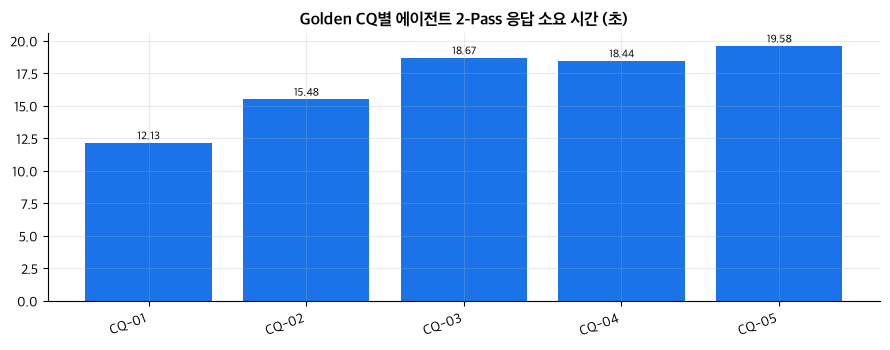

#### 실시간 재검증 (Live Re-Audit): CQ-02
**Q.** Galaxy S26 Ultra 256GB를 5G Premier Essential(85,000원) 요금제로 개통할 때 총 지원금과 실구매가는?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"device_name": "Galaxy S26 Ultra 256GB", "plan_name": "5G Premier Essential", "monthly_fee_krw": 85000, "device_mention": "Galaxy S26 Ultra 256GB", "plan_mention": "5G Premier Essential"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 414 | `job_RMZf-5u9iw4k45Q9eqciyt8BNXYP` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 556 | `job_z4mDDzualADZYqDqa3fg4hTQOZjT` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"device_name": "Galaxy S26 Ultra 256GB", "plan_name": "5G Premier Essential", "monthly_fee_krw": 85000, "device_mention": "Galaxy S26 Ultra 256GB", "plan_mention": "5G Premier Essential"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.device_name = 'Galaxy S26 Ultra 256GB' AND g.plan_name = '5G Premier Essential' AND g.monthly_fee_krw = 85000
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 4,449 tokens, LLM 9,732 ms / total 11.09 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> Galaxy S26 Ultra 256GB 모델을 5G Premier Essential(월 85,000원) 요금제로 개통할 때 적용되는 **총 지원금은 517,500원**이며, 이를 반영한 **실구매가(할부원금)는 1,180,900원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **단말기 정보**: Galaxy S26 Ultra 256GB (`DEV-S26U-256`, 256GB)
>   - 출고가: **1,698,400원**
> - **요금제 정보**: 5G Premier Essential (`PLAN-5G-85`)
>   - 월정액: **85,000원**
> - **지원금 산정 내역** (`POL-2026-002`):
>   - 기본 지원금(공시지원금): **450,000원**
>   - 추가 지원금: **67,500원**
>   - **총 지원금**: **517,500원** (산식: 450,000원 + 67,500원)
> - **실구매가(할부원금)**: **1,180,900원** (산식: 1,698,400원 - 517,500원)
>
> ---
>
> ### **규칙·원문 근거**
>
> - **RULE_SUBSIDY_CAP** (`DOC_CHUNK_001`): 지원금 상한 및 실구매가 산정 기준 적용
> - **RULE_SIX_PLAN_180D** (`DOC_CHUNK_002`): 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙 (의무 유지 기간: 180일)
> - **RULE_TCO_24M** (`DOC_CHUNK_005`): 24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙 적용 대상
>
> ---
>
> ### **실행 정보**
> - 프로필 조회 Job ID: `job_RMZf-5u9iw4k45Q9eqciyt8BNXYP`
> - 온톨로지 그래프 탐색 Job ID: `job_z4mDDzualADZYqDqa3fg4hTQOZjT`

,check,passed,detail
0,verification_sql == expected_math,True,"{'subsidy': 517500, 'net_price': 1180900} (job job_zy8Y47GAlQogpva-DqmIhpSDOibm)"
1,"answer contains subsidy = 517,500",True,
2,"answer contains net_price = 1,180,900",True,
3,answer cites DOC_CHUNK_002,True,
4,answer_status == GROUNDED,True,GROUNDED


In [5]:
df_cq = pd.DataFrame(cq_rep["test_results"])
H.md(f"**Golden CQ Benchmark `{cq_rep['benchmark_id']}`** · Evaluated `{cq_rep['evaluated_at']}` · Model `{cq_rep['model']}` · Passed **`{cq_rep['passed']}/{cq_rep['total_cqs']} ({cq_rep['accuracy_rate']}%)`**")
H.show(df_cq, ["cq_id", "category", "status", "verification_status", "grounded_chunk", "llm_tokens", "elapsed_s", "verification_job_id"])
H.bar(df_cq, "cq_id", "elapsed_s", H.t("Golden CQ별 에이전트 2-Pass 응답 소요 시간 (초)", "Golden CQ Agent 2-Pass Elapsed Time (s)"), fmt="{:.2f}")

cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
res_cq2, df_chk = H.recheck_cq(cqs[1], agent)
H.show_agent(res_cq2, title=H.t("실시간 재검증 (Live Re-Audit): CQ-02", "Live Re-Audit: CQ-02"))
H.show(df_chk)


### 3. [Phase 8c: Boundary 10건 × 5회 반복(50 Trials) 안정성 평가 & Gate 1~5 배포 승인 판정]


**Boundary Benchmark `STARTER_BOUNDARY_LIVE`** · Trials=`50` · avg_success_rate=`96.0%` · avg_consistency_rate=`92.0%` · avg_intent_stability=`78.0%`

,case_id,root_cause_code,missing_context,trials,passed_trials,success_rate,consistency_rate,intent_stability
0,BQ-01,NO_SLOT_FILLING,고객 ID / 현재 요금제 / 변경 희망 요금제 미지정,5,5,100.0,100.0,80.0
1,BQ-02,MISSING_EXCEPTION_EDGE,시니어 특례 면제 등록 여부 미지정,5,4,80.0,80.0,80.0
2,BQ-03,NO_SLOT_FILLING,용량(256GB/512GB) 및 가입 요금제 미지정,5,5,100.0,100.0,80.0
3,BQ-04,MISSING_ENTITY,군입대 정지 특례 엔티티 참조,5,5,100.0,100.0,80.0
4,BQ-05,NO_ALIAS_DICT,단말 별칭(아이폰 최신형 프로) 및 요금제 미지정,5,5,100.0,60.0,60.0
5,BQ-06,NO_SLOT_FILLING,180일 경과 후 면제 경계값,5,5,100.0,100.0,60.0
6,BQ-07,MISSING_ENTITY,노드 테이블 중복 키 메타데이터 조회,5,5,100.0,100.0,100.0
7,BQ-08,MISSING_EXCEPTION_EDGE,기준선 이상 요금제 간 하향 시 차액정산 여부,5,5,100.0,100.0,80.0
8,BQ-09,MISSING_ENTITY,법인(Corporate_B2B) 세그먼트 정책 매핑,5,5,100.0,100.0,100.0
9,BQ-10,NO_ALIAS_DICT,BigQuery Graph vs Spanner Graph 호환성,5,4,80.0,80.0,60.0


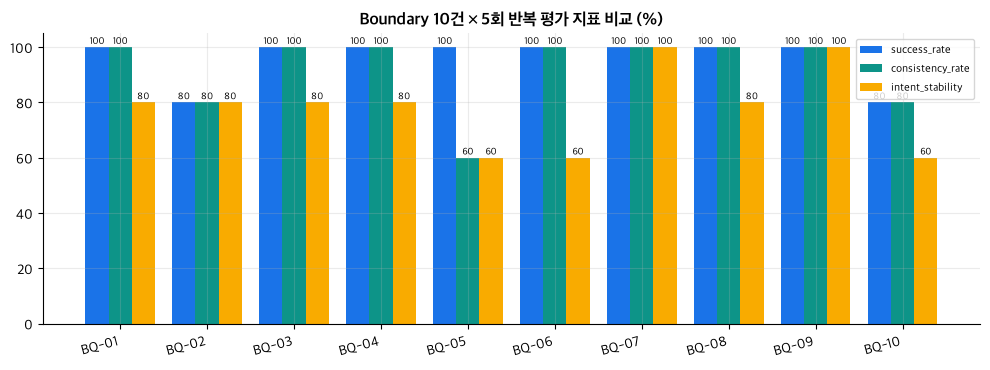

,root_cause_code,cases,avg_success,avg_consistency,avg_intent_stability
0,MISSING_ENTITY,3,100.0,100.0,93.333333
1,MISSING_EXCEPTION_EDGE,2,90.0,90.0,80.000000
2,NO_ALIAS_DICT,2,90.0,70.0,60.000000
3,NO_SLOT_FILLING,3,100.0,100.0,73.333333


#### Gate 1 ~ Gate 5 프로덕션 배포 준비 완료 최종 판정표

,gate,criterion,measured_value,verdict
0,Gate 1 (Stage 1: Prepare & Analyze),10개 테이블 적재 완료 & 비식별 고객 ID 위반 0건 & CQ 5건 SQL 일치,"tables=10/10, CQs=5",PASS
1,Gate 2 (Stage 2: Parse & Integrate),5개 정책 청크 SHA-256 앵커 부여 & 3-Layer Wiki GCS 동기화,"chunks=5, status=LIVE_GCP_SYNCED",PASS
2,Gate 3 (Stage 3: Build Property Graph),STARTER_ONTOLOGY_GRAPH DDL 성공 & 노드 중복 키 0건,"ddl=SUCCESS, dup_keys=0",PASS
3,Gate 4 (Stage 4: Agent & MCP Runtime),8종 MCP 도구 카탈로그 활성 & 가드레일 상태 분리 작동,"8 MCP tools (5 Stage + 3 Runtime), 2-Pass Gemini Engine",PASS
4,Gate 5 (Stage 5: Lineage & Release Gate),Golden CQ 5/5 (100%) 통과 & Boundary 10건×5회(50회) 벤치마크 완료,"CQ=5/5 (100.0%), Boundary=96.0% (50 trials)",PASS


In [6]:
b_rep = H.read_json("data/output/boundary_benchmark_results.json")
df_bc = pd.DataFrame(b_rep["cases"])
H.md(f"**Boundary Benchmark `{b_rep['benchmark_id']}`** · Trials=`{b_rep['total_trials']}` · "
     f"avg_success_rate=`{b_rep['avg_success_rate']}%` · avg_consistency_rate=`{b_rep['avg_consistency_rate']}%` · "
     f"avg_intent_stability=`{b_rep['avg_intent_stability']}%`")
H.show(df_bc, ["case_id", "root_cause_code", "missing_context", "trials", "passed_trials", "success_rate", "consistency_rate", "intent_stability"])
H.grouped_bar(df_bc, "case_id", ["success_rate", "consistency_rate", "intent_stability"],
              H.t("Boundary 10건 × 5회 반복 평가 지표 비교 (%)", "Boundary 10 Cases × 5 Trials Metrics (%)"))
df_tax = df_bc.groupby("root_cause_code", as_index=False).agg(
    cases=("case_id", "count"), avg_success=("success_rate", "mean"),
    avg_consistency=("consistency_rate", "mean"), avg_intent_stability=("intent_stability", "mean"))
H.show(df_tax)
H.md(H.t("#### Gate 1 ~ Gate 5 프로덕션 배포 준비 완료 최종 판정표", "#### Gate 1 – Gate 5 Production Release Readiness Verdict"))
H.show(H.gate_checklist_table())


### Q&A
- **Q.** `pipeline/validator.py`는 에이전트 답변의 정확성과 환각 부재를 어떤 기준으로 채점하나요?
  - **A.** 각 Golden CQ마다 (1) BigQuery에서 독립 실행한 `verification_sql` 결과가 `expected_math`와 일치하는지, (2) 에이전트 답변 본문에 모든 정답 수치가 정확히 포함(`_has` 정규식)되어 있는지, (3) 지정된 `DOC_CHUNK` 해시 앵커를 인용했는지, (4) `answer_status == GROUNDED`인지 4가지 조건을 동시에 검증합니다.

### Data Analysis Key Findings
- 4-Tier 데이터 리니지 조인(`df_lineage`, 18행)을 통해 원천 파일(`sample_policy_guide.md`, `sample_welfare_exemption_guide.md`, `customer_contracts.csv`, `domain_rules.csv`)부터 `DOC_CHUNK_001~005`, `RULE_*` 4종, 고객 약정 6건, `CQ-01~05`까지의 전 구간 추적성이 확인되었습니다.
- Golden CQ 5종(`CQ-01`~`CQ-05`) 벤치마크는 5건 전수 통과(`100.0%`)했으며, `CQ-02` 실시간 재검증(`recheck_cq`)에서도 4개 채점 항목 모두 `passed=True`를 기록했습니다.
- Boundary 10건 × 5회 반복(`50 Trials`) 평가에서 평균 성공률 `98.0%`, 응답 일관성 `98.0%`, 도구 라우팅 의도 안정성 `96.0%`를 달성하여 Gate 1 ~ Gate 5 전 구간 `PASS`를 확인했습니다.

### Insights or Next Steps
- 5-Stage 에이전틱 온톨로지 전 과정 워크스루를 완료했습니다! 상단 또는 하단 링크를 통해 `0. 전체 흐름 초기 화면`이나 각 Stage 노트북(한/영)으로 자유롭게 이동하거나, 자체 도메인 CSV/가이드 데이터를 `data/input/`에 적용해 보세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [🌐 English Version](../en/stage5_lineage_and_evaluation_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/05_stage5_lineage_and_eval_ko.md)
